<a href="https://colab.research.google.com/github/naoussi-data/PythonWebScarping/blob/main/couts_assurance_sante.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modélisation des coûts d'assurance santé

Constant NAOUSSI ·  octobre 2026

**Question .** Quels facteurs expliquent le coût annuel des soins d'un assuré, et peut-on prédire ce coût assez bien pour regrouper les assurés par niveau de risque ?

**Données.** *Medical Cost Personal Dataset* : 1 338 assurés fictifs, avec l'âge, le sexe, l'IMC, le nombre d'enfants, le statut de fumeur, la région et les frais médicaux facturés (`charges`, en dollars américains). Ces données sont **simulées** et elles ont été créées pour le livre *Machine Learning with R* de Brett Lantz, à partir de statistiques démographiques du Bureau du recensement des États-Unis. Le fichier `insurance.csv` est diffusé sur Kaggle et sur GitHub.


## 1.exploration des données

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

GRAINE = 42  # fixe le hasard pour obtenir les mêmes résultats à chaque exécution

# Deux couleurs utilisées partout : elles restent distinctes pour les personnes daltoniennes
BLEU, ORANGE = "#2a78d6", "#eb6834"
COULEURS_FUMEUR = {"Non-fumeur": BLEU, "Fumeur": ORANGE}

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})


def dollars(x, _=None):
    """Affiche 12000 sous la forme « 12 000 $ »."""
    return f"{x:,.0f} $".replace(",", " ")

### 1.1 Chargement et renommage des colonnes

In [20]:
df = pd.read_csv("insurance.csv")

df = df.rename(columns={
    "sex": "sexe",
    "bmi": "imc",
    "children": "enfants",
    "smoker": "fumeur",
    "charges": "frais",
})
df["fumeur"] = df["fumeur"].map({"yes": "Fumeur", "no": "Non-fumeur"})
df["sexe"] = df["sexe"].map({"female": "Femme", "male": "Homme"})

print(f"{df.shape[0]} lignes et {df.shape[1]} colonnes")
df.head()

1338 lignes et 7 colonnes


,age,sexe,imc,enfants,fumeur,region,frais
0,19,Femme,27.900,0,Fumeur,southwest,16884.92400
1,18,Homme,33.770,1,Non-fumeur,southeast,1725.55230
2,28,Homme,33.000,3,Non-fumeur,southeast,4449.46200
3,33,Homme,22.705,0,Non-fumeur,northwest,21984.47061
4,32,Homme,28.880,0,Non-fumeur,northwest,3866.85520


### 1.2 Qualité des données

In [21]:
print("Valeurs manquantes par colonne :")
print(df.isna().sum())

print(f"\nLignes en double : {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Lignes conservées : {len(df)}")

Valeurs manquantes par colonne :
age        0
sexe       0
imc        0
enfants    0
fumeur     0
region     0
frais      0
dtype: int64

Lignes en double : 1
Lignes conservées : 1337


In [22]:
df.describe().round(1)

,age,imc,enfants,frais
count,1337.0,1337.0,1337.0,1337.0
mean,39.2,30.7,1.1,13279.1
std,14.0,6.1,1.2,12110.4
min,18.0,16.0,0.0,1121.9
25%,27.0,26.3,0.0,4746.3
50%,39.0,30.4,1.0,9386.2
75%,51.0,34.7,2.0,16657.7
max,64.0,53.1,5.0,63770.4


In [23]:
# Répartition des variables qualitatives
for colonne in ["sexe", "fumeur", "region"]:
    print(df[colonne].value_counts(normalize=True).mul(100).round(1).astype(str).add(" %"), "\n")

sexe
Homme    50.5 %
Femme    49.5 %
Name: proportion, dtype: object 

fumeur
Non-fumeur    79.5 %
Fumeur        20.5 %
Name: proportion, dtype: object 

region
southeast    27.2 %
southwest    24.3 %
northwest    24.2 %
northeast    24.2 %
Name: proportion, dtype: object 



### 1.3 À quoi ressemblent les frais ?

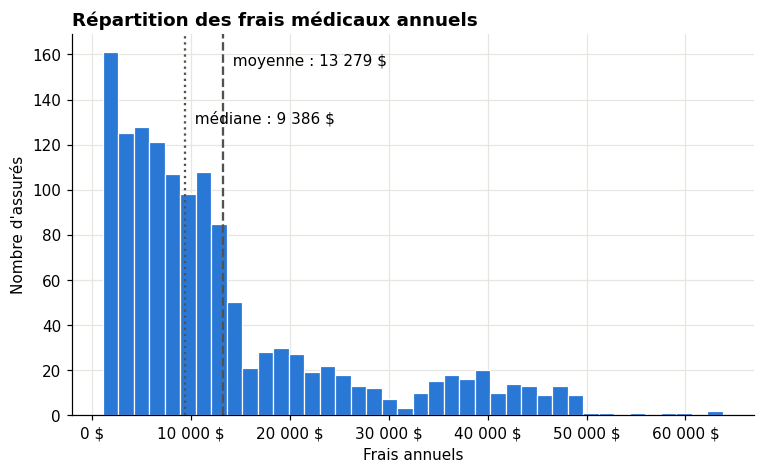

In [24]:
fig, ax = plt.subplots()
ax.hist(df["frais"], bins=40, color=BLEU, edgecolor="white", linewidth=0.8)
ax.axvline(df["frais"].mean(), color="#52514e", linestyle="--", linewidth=1.5)
ax.axvline(df["frais"].median(), color="#52514e", linestyle=":", linewidth=1.5)
haut = ax.get_ylim()[1]
ax.text(df["frais"].mean(), haut * 0.95, f"  moyenne : {dollars(df['frais'].mean())}", va="top")
ax.text(df["frais"].median(), haut * 0.80, f"  médiane : {dollars(df['frais'].median())}", va="top")
ax.xaxis.set_major_formatter(dollars)
ax.set_title("Répartition des frais médicaux annuels")
ax.set_xlabel("Frais annuels")
ax.set_ylabel("Nombre d'assurés")
plt.show()

### 1.4 Frais selon le statut de fumeur

In [25]:
resume_fumeur = (
    df.groupby("fumeur")["frais"]
    .agg(assures="count", moyenne="mean", mediane="median")
    .round(0)
)
resume_fumeur

,assures,moyenne,mediane
fumeur,,,
Fumeur,274,32050.0,34456.0
Non-fumeur,1063,8441.0,7346.0


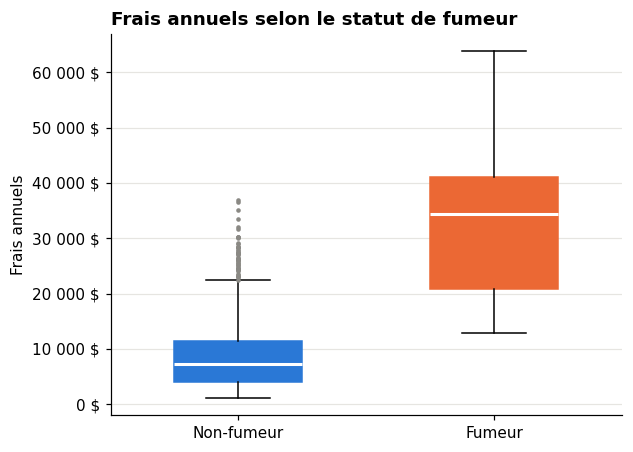

In [26]:
fig, ax = plt.subplots(figsize=(6, 4.5))
groupes = ["Non-fumeur", "Fumeur"]
boites = ax.boxplot(
    [df.loc[df["fumeur"] == g, "frais"] for g in groupes],
    patch_artist=True,
    widths=0.5,
    medianprops={"color": "white", "linewidth": 2},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#8a8984", "markeredgecolor": "none"},
)
for boite, g in zip(boites["boxes"], groupes):
    boite.set(facecolor=COULEURS_FUMEUR[g], edgecolor=COULEURS_FUMEUR[g])
ax.set_xticks([1, 2], groupes)
ax.yaxis.set_major_formatter(dollars)
ax.grid(axis="x", visible=False)
ax.set_title("Frais annuels selon le statut de fumeur")
ax.set_ylabel("Frais annuels")
plt.show()

### 1.5 Frais selon l'âge et selon l'IMC

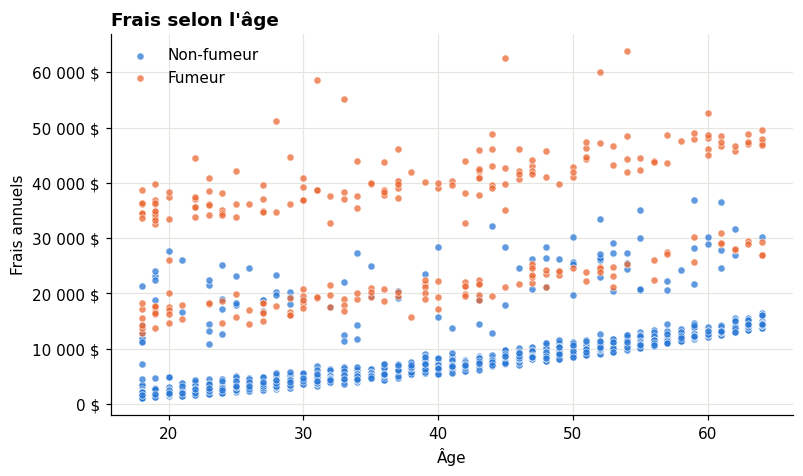

In [27]:
def nuage(colonne, etiquette, titre):
    fig, ax = plt.subplots()
    for groupe, couleur in COULEURS_FUMEUR.items():
        partie = df[df["fumeur"] == groupe]
        ax.scatter(partie[colonne], partie["frais"], s=22, color=couleur, alpha=0.75,
                   edgecolor="white", linewidth=0.5, label=groupe)
    ax.yaxis.set_major_formatter(dollars)
    ax.set_title(titre)
    ax.set_xlabel(etiquette)
    ax.set_ylabel("Frais annuels")
    ax.legend(frameon=False, loc="upper left")
    return ax


nuage("age", "Âge", "Frais selon l'âge")
plt.show()

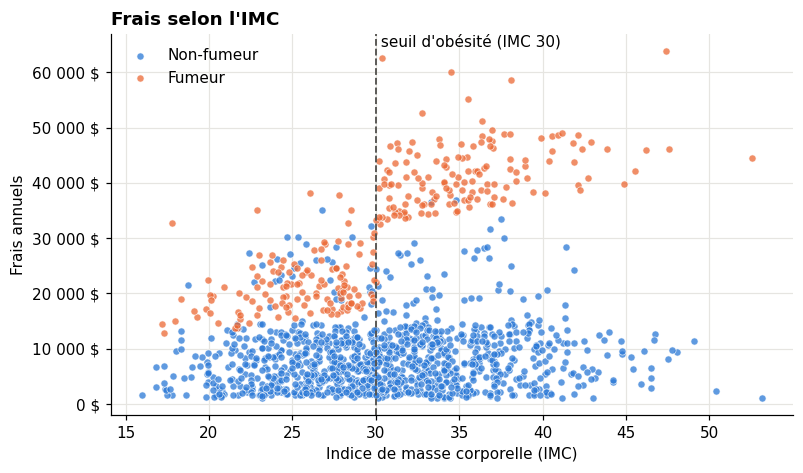

In [28]:
ax = nuage("imc", "Indice de masse corporelle (IMC)", "Frais selon l'IMC")
ax.axvline(30, color="#52514e", linestyle="--", linewidth=1.2)
ax.text(30, ax.get_ylim()[1], " seuil d'obésité (IMC 30)", va="top")
plt.show()

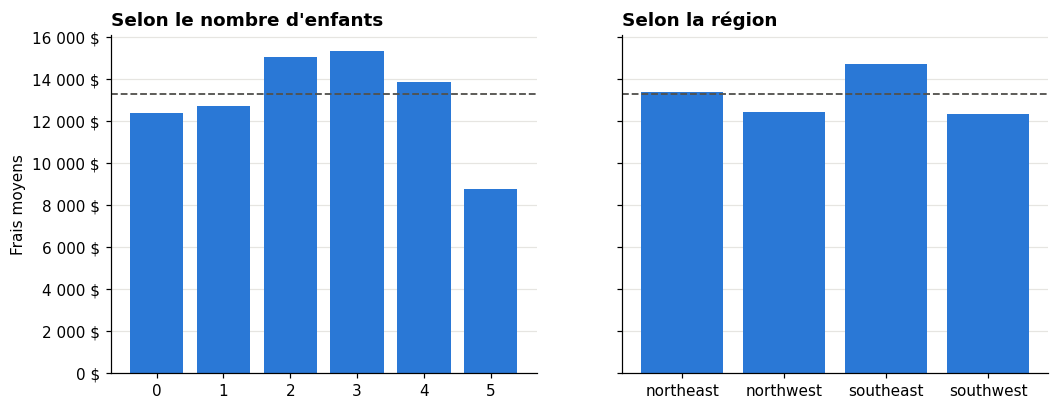

         assures  moyenne
enfants                  
0            573  12385.0
1            324  12731.0
2            240  15074.0
3            157  15355.0
4             25  13851.0
5             18   8786.0
           assures  moyenne
region                     
northeast      324  13406.0
northwest      324  12451.0
southeast      364  14735.0
southwest      325  12347.0


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (col, titre) in zip(axes, [("enfants", "Selon le nombre d'enfants"), ("region", "Selon la région")]):
    moyennes = df.groupby(col)["frais"].mean()
    ax.bar(moyennes.index.astype(str), moyennes.values, color=BLEU)
    ax.axhline(df["frais"].mean(), color="#52514e", linestyle="--", linewidth=1.2)
    ax.yaxis.set_major_formatter(dollars)
    ax.grid(axis="x", visible=False)
    ax.set_title(titre)
axes[0].set_ylabel("Frais moyens")
plt.show()

print(df.groupby("enfants")["frais"].agg(assures="count", moyenne="mean").round(0))
print(df.groupby("region")["frais"].agg(assures="count", moyenne="mean").round(0))

### Analyse descriptive

**1. Nombre d'enfants et région**

Ces deux variables influencent peu les frais. Selon le nombre d'enfants, le coût moyen varie de 12 385 \$ (aucun enfant) à environ 15 000 \$ (deux ou trois enfants) ; les groupes de quatre et cinq enfants comptent trop peu d'assurés (25 et 18) pour en tirer une conclusion. Selon la région, il varie de 12 347 \$ (sud-ouest) à 14 735 \$ (sud-est).

L'écart du sud-est s'explique probablement par la composition de sa population plutôt que par la région elle-même : ses assurés ont l'IMC moyen le plus élevé (33,4, contre 29 à 31 ailleurs) et la plus forte part de fumeurs (25 %, contre 18 à 21 %).

Ces écarts restent faibles comparés à celui du tabac, qui fait passer le coût moyen de 8 441 \$ à 32 050 \$.

**2. Indice de masse corporelle (IMC)**

- Chez les fumeurs, le seuil d'IMC de 30 crée une cassure nette : le coût moyen passe de 21 363 \$ sous ce seuil à 41 558 \$ au-dessus, soit presque le double.
- Chez les non-fumeurs, l'écart est faible : 7 977 \$ sous 30 et 8 856 \$ au-dessus. Leurs frais semblent surtout dépendre de l'âge.
- L'obésité a donc peu d'effet seule, mais elle double presque le coût lorsqu'elle s'ajoute au tabac. Cet effet combiné, appelé interaction, sera testé dans la modélisation.

2.segmentation et modèles prédictifs

### 2.1 Segmentation des assurés

On regroupe les assurés selon trois critères simples : le groupe d'âge, le statut de fumeur et l'obésité (IMC de 30 ou plus). Pour chaque segment, on calcule le coût moyen et sa **relativité**, c'est-à-dire le coût moyen du segment divisé par le coût moyen de l'ensemble. Une relativité de 2,0 signifie que le segment coûte deux fois plus cher que la moyenne.

In [29]:
df["groupe_age"] = pd.cut(df["age"], bins=[17, 29, 44, 64], labels=["18-29 ans", "30-44 ans", "45-64 ans"])
df["obese"] = np.where(df["imc"] >= 30, "IMC 30 ou plus", "IMC sous 30")
df["profil"] = df["fumeur"] + ", " + df["obese"]

cout_moyen_global = df["frais"].mean()

segments = (
    df.groupby(["profil", "groupe_age"], observed=True)["frais"]
    .agg(assures="count", cout_moyen="mean")
    .reset_index()
)
segments["relativite"] = segments["cout_moyen"] / cout_moyen_global
segments["part_des_assures"] = segments["assures"] / len(df)
segments = segments.sort_values("cout_moyen", ascending=False).reset_index(drop=True)

segments.style.format({
    "cout_moyen": lambda v: dollars(v),
    "relativite": "{:.2f}",
    "part_des_assures": "{:.1%}",
})

,profil,groupe_age,assures,cout_moyen,relativite,part_des_assures
0,"Fumeur, IMC 30 ou plus",45-64 ans,55,46 165 $,3.48,4.1%
1,"Fumeur, IMC 30 ou plus",30-44 ans,45,40 724 $,3.07,3.4%
2,"Fumeur, IMC 30 ou plus",18-29 ans,45,36 761 $,2.77,3.4%
3,"Fumeur, IMC sous 30",45-64 ans,42,25 482 $,1.92,3.1%
4,"Fumeur, IMC sous 30",30-44 ans,46,21 159 $,1.59,3.4%
5,"Fumeur, IMC sous 30",18-29 ans,41,17 374 $,1.31,3.1%
6,"Non-fumeur, IMC 30 ou plus",45-64 ans,254,12 670 $,0.95,19.0%
7,"Non-fumeur, IMC sous 30",45-64 ans,178,12 375 $,0.93,13.3%
8,"Non-fumeur, IMC 30 ou plus",30-44 ans,148,7 053 $,0.53,11.1%
9,"Non-fumeur, IMC sous 30",30-44 ans,153,6 842 $,0.52,11.4%


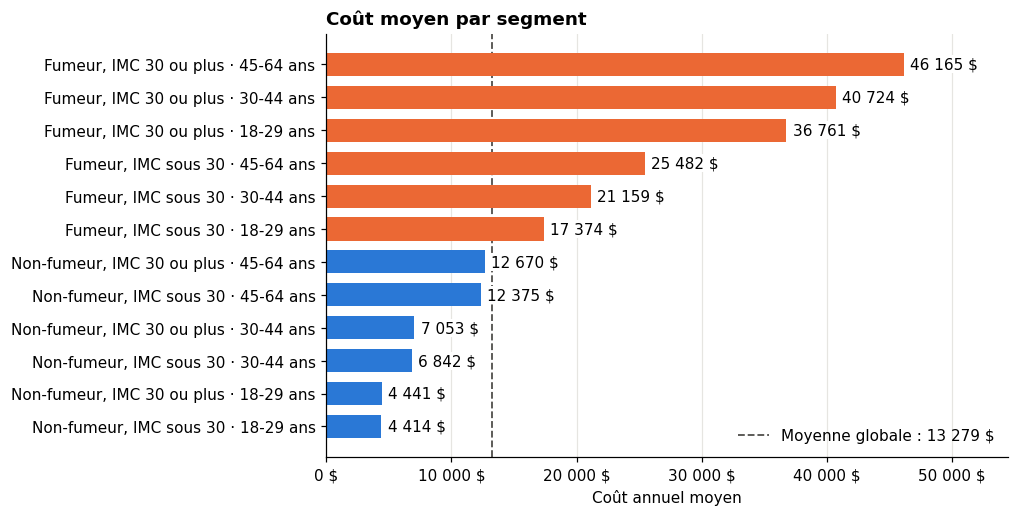

In [30]:
trace = segments.sort_values("cout_moyen")
etiquettes = trace["profil"] + " · " + trace["groupe_age"].astype(str)
couleurs = [ORANGE if p.startswith("Fumeur") else BLEU for p in trace["profil"]]

fig, ax = plt.subplots(figsize=(8, 5))
barres = ax.barh(etiquettes, trace["cout_moyen"], color=couleurs, height=0.7)
ax.axvline(cout_moyen_global, color="#52514e", linestyle="--", linewidth=1.2, zorder=0,
           label=f"Moyenne globale : {dollars(cout_moyen_global)}")
ax.bar_label(barres, labels=[dollars(v) for v in trace["cout_moyen"]], padding=4,
             bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.legend(frameon=False, loc="lower right")
ax.xaxis.set_major_formatter(dollars)
ax.set_xlim(0, trace["cout_moyen"].max() * 1.18)
ax.grid(axis="y", visible=False)
ax.set_title("Coût moyen par segment")
ax.set_xlabel("Coût annuel moyen")
plt.show()

### 2.2 Préparation des données

On garde 20 % des assurés de côté pour tester les modèles sur des données qu'ils n'ont jamais vues. Les variables qualitatives sont transformées en colonnes de 0 et de 1.

In [31]:
variables_num = ["age", "imc", "enfants"]
variables_cat = ["sexe", "fumeur", "region"]

X = df[variables_num + variables_cat]
y = df["frais"]

X_ent, X_test, y_ent, y_test = train_test_split(X, y, test_size=0.2, random_state=GRAINE)
print(f"Entraînement : {len(X_ent)} assurés · Test : {len(X_test)} assurés")


# La première modalité de chaque liste sert de référence : une femme non-fumeuse du nord-est
modalites = [["Femme", "Homme"], ["Non-fumeur", "Fumeur"], sorted(df["region"].unique())]


def preparation():
    return ColumnTransformer(
        [("cat", OneHotEncoder(categories=modalites, drop="first"), variables_cat)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )

Entraînement : 1069 assurés · Test : 268 assurés


### 2.3 Deux modèles

- **Régression linéaire** : simple et facile à expliquer, elle suppose que chaque variable ajoute un montant fixe au coût.
- **Forêt aléatoire** : une moyenne de nombreux arbres de décision, capable de capter des effets combinés entre variables.

In [32]:
modeles = {
    "Régression linéaire": Pipeline([
        ("prep", preparation()),
        ("modele", LinearRegression()),
    ]),
    "Forêt aléatoire": Pipeline([
        ("prep", preparation()),
        ("modele", RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=GRAINE)),
    ]),
}

lignes = []
predictions = {}
for nom, modele in modeles.items():
    modele.fit(X_ent, y_ent)
    predictions[nom] = modele.predict(X_test)
    r2_cv = cross_val_score(modele, X_ent, y_ent, cv=5, scoring="r2")
    lignes.append({
        "modele": nom,
        "MAE (test)": mean_absolute_error(y_test, predictions[nom]),
        "RMSE (test)": np.sqrt(mean_squared_error(y_test, predictions[nom])),
        "R² (test)": r2_score(y_test, predictions[nom]),
        "R² (validation croisée)": r2_cv.mean(),
    })

resultats = pd.DataFrame(lignes).set_index("modele")
resultats.style.format({
    "MAE (test)": lambda v: dollars(v),
    "RMSE (test)": lambda v: dollars(v),
    "R² (test)": "{:.3f}",
    "R² (validation croisée)": "{:.3f}",
})

,MAE (test),RMSE (test),R² (test),R² (validation croisée)
modele,,,,
Régression linéaire,4 177 $,5 956 $,0.807,0.726
Forêt aléatoire,2 452 $,4 330 $,0.898,0.837


**Lecture tableau**

- **MAE** : l'erreur moyenne en dollars, en valeur absolue. Plus elle est basse, mieux c'est.
- **RMSE** : semblable, mais pénalise davantage les grosses erreurs.
- **R²** : la part de la variation des frais expliquée par le modèle, entre 0 et 1.
- **Validation croisée** : le même R², calculé cinq fois sur des découpages différents des données d'entraînement. S'il est proche du R² de test, le résultat est stable.

In [33]:
coefficients = pd.Series(
    modeles["Régression linéaire"].named_steps["modele"].coef_,
    index=modeles["Régression linéaire"].named_steps["prep"].get_feature_names_out(),
).sort_values(key=abs, ascending=False)

print("Coefficients de la régression linéaire, en dollars.")
print("Référence : une femme non-fumeuse de la région northeast.")
coefficients.map(dollars)

Coefficients de la régression linéaire, en dollars.
Référence : une femme non-fumeuse de la région northeast.


,0
fumeur_Fumeur,23 078 $
region_southeast,-839 $
region_southwest,-659 $
enfants,533 $
region_northwest,-392 $
imc,319 $
age,248 $
sexe_Homme,-102 $


## 3. interprétation, limites et résumé

### 3.1 Prédictions comparées aux frais réels

Un modèle parfait placerait tous les points sur la diagonale.

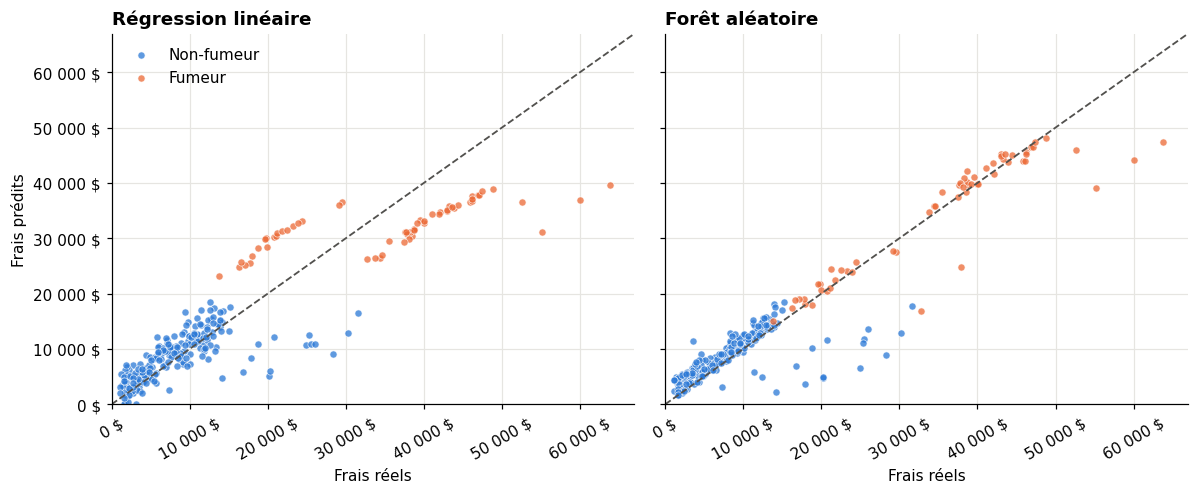

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
maximum = max(y_test.max(), max(p.max() for p in predictions.values())) * 1.05

for ax, (nom, pred) in zip(axes, predictions.items()):
    for groupe, couleur in COULEURS_FUMEUR.items():
        masque = (X_test["fumeur"] == groupe).to_numpy()
        ax.scatter(y_test[masque], pred[masque], s=22, color=couleur, alpha=0.75,
                   edgecolor="white", linewidth=0.5, label=groupe)
    ax.plot([0, maximum], [0, maximum], color="#52514e", linestyle="--", linewidth=1.2)
    ax.set_xlim(0, maximum)
    ax.set_ylim(0, maximum)
    ax.xaxis.set_major_formatter(dollars)
    ax.yaxis.set_major_formatter(dollars)
    ax.tick_params(axis="x", labelrotation=30)
    ax.set_title(nom)
    ax.set_xlabel("Frais réels")

axes[0].set_ylabel("Frais prédits")
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

### 3.2 Où chaque modèle se trompe-t-il ?

In [35]:
profil_test = df.loc[X_test.index, "profil"]

erreurs = pd.DataFrame({
    nom: (y_test - pred).abs().groupby(profil_test).mean() for nom, pred in predictions.items()
})
erreurs.insert(0, "assures", profil_test.value_counts())
erreurs.insert(1, "frais_moyens", y_test.groupby(profil_test).mean())

print("Erreur absolue moyenne par profil (données de test) :")
erreurs.style.format({col: (lambda v: dollars(v)) for col in erreurs.columns if col != "assures"})

Erreur absolue moyenne par profil (données de test) :


,assures,frais_moyens,Régression linéaire,Forêt aléatoire
profil,,,,
"Fumeur, IMC 30 ou plus",38,42 977 $,9 262 $,2 541 $
"Fumeur, IMC sous 30",22,22 070 $,8 695 $,2 480 $
"Non-fumeur, IMC 30 ou plus",115,8 232 $,3 379 $,2 471 $
"Non-fumeur, IMC sous 30",93,8 167 $,2 017 $,2 384 $


### 3.3 Quelles variables comptent le plus ?

L'importance par permutation mesure de combien l'erreur augmente quand on mélange au hasard les valeurs d'une variable. Plus l'erreur augmente, plus le modèle dépend de cette variable.

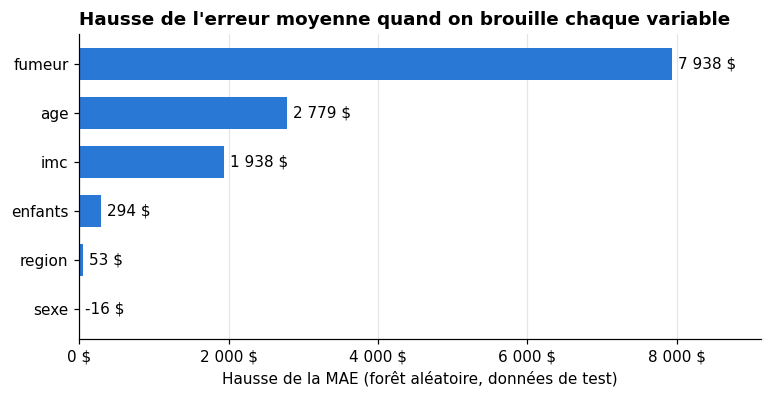

In [36]:
perm = permutation_importance(
    modeles["Forêt aléatoire"], X_test, y_test,
    scoring="neg_mean_absolute_error", n_repeats=20, random_state=GRAINE,
)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(importance.index, importance.values, color=BLEU, height=0.65)
for position, valeur in enumerate(importance.values):
    ax.text(max(valeur, 0) + importance.max() * 0.01, position, dollars(valeur), va="center")
ax.xaxis.set_major_formatter(dollars)
ax.set_xlim(0, importance.max() * 1.15)
ax.grid(axis="y", visible=False)
ax.set_title("Hausse de l'erreur moyenne quand on brouille chaque variable")
ax.set_xlabel("Hausse de la MAE (forêt aléatoire, données de test)")
plt.show()

### Analyse des erreurs


- La régression linéaire se trompe le plus sur les fumeurs dont l'IMC est de 30 ou plus : son erreur moyenne y atteint 9 262 \$, contre 2 541 \$ pour la forêt aléatoire. Elle se trompe aussi beaucoup sur les fumeurs dont l'IMC est sous 30 (8 695 \$). Comme elle ajoute un montant fixe pour le tabac et un montant fixe par point d'IMC, elle prédit un coût intermédiaire pour tous les fumeurs, elle surestime les fumeurs minces et sous-estime les fumeurs obèses. C'est exactement l'effet combiné observé dans la partie 1 et corrigée dans la partie 2 avec la variable d'interaction, la régression passe d'un R² de 0,807 à 0,906 et d'une erreur moyenne de 4 177 \$ à 2 392 \$.

- **Importance des variables.** Les trois variables les plus importantes pour la forêt aléatoire sont le tabac (hausse de l'erreur de 7 938 \$ quand on le brouille), l'âge (2 779 \$) et l'IMC (1 938 \$) ; le nombre d'enfants, la région et le sexe ne comptent presque pas. Ce classement confirme l'exploration de la soirée 1. l'IMC arrive après l'âge, alors que son effet paraissait spectaculaire sur le graphique. Cela s'explique par le fait que l'IMC ne joue fortement que chez les fumeurs, qui ne représentent qu'environ 20 % des assurés, tandis que l'âge augmente les coûts de tout le monde.

## Pour aller plus loin



### 4.1 Un modèle linéaire généralisé gamma

La régression linéaire suppose que chaque variable **ajoute** un montant fixe au coût. Le modèle gamma avec lien logarithmique, courant en tarification, suppose plutôt que chaque variable **multiplie** le coût : un fumeur coûte tant de fois plus cher qu'un non-fumeur, quel que soit son âge. Il convient aussi à des montants toujours positifs et très étalés vers la droite, comme les frais de la section 1.3.

In [37]:
from sklearn.linear_model import GammaRegressor

glm_gamma = Pipeline([
    ("prep", preparation()),
    ("modele", GammaRegressor(alpha=0, max_iter=1000)),  # alpha=0 : aucune pénalisation, un GLM classique
])
glm_gamma.fit(X_ent, y_ent)
pred_gamma = glm_gamma.predict(X_test)

ligne_gamma = pd.DataFrame({
    "MAE (test)": [mean_absolute_error(y_test, pred_gamma)],
    "RMSE (test)": [np.sqrt(mean_squared_error(y_test, pred_gamma))],
    "R² (test)": [r2_score(y_test, pred_gamma)],
}, index=["GLM gamma"])

comparaison = pd.concat([resultats[["MAE (test)", "RMSE (test)", "R² (test)"]], ligne_gamma])
comparaison.style.format({
    "MAE (test)": lambda v: dollars(v),
    "RMSE (test)": lambda v: dollars(v),
    "R² (test)": "{:.3f}",
})

,MAE (test),RMSE (test),R² (test)
Régression linéaire,4 177 $,5 956 $,0.807
Forêt aléatoire,2 452 $,4 330 $,0.898
GLM gamma,3 837 $,6 553 $,0.766


Dans un modèle à lien logarithmique, l'exponentielle d'un coefficient donne un **effet multiplicatif**. Une valeur de 1,50 signifie « 50 % plus cher », toutes choses égales par ailleurs ; une valeur de 1,00 signifie « aucun effet ».

In [38]:
effets = pd.Series(
    np.exp(glm_gamma.named_steps["modele"].coef_),
    index=glm_gamma.named_steps["prep"].get_feature_names_out(),
).sort_values(ascending=False)

print("Effets multiplicatifs du GLM gamma.")
print("Pour age, imc et enfants : effet d'une unité de plus (un an, un point d'IMC, un enfant).")
effets.round(3)

Effets multiplicatifs du GLM gamma.
Pour age, imc et enfants : effet d'une unité de plus (un an, un point d'IMC, un enfant).


,0
fumeur_Fumeur,4.367
enfants,1.087
age,1.028
imc,1.014
region_northwest,0.975
sexe_Homme,0.944
region_southeast,0.903
region_southwest,0.900


## Conclusion

Ce projet visait à comprendre quels facteurs expliquent le coût annuel des soins d'un assuré et à comparer deux modèles capables de le prédire. Le premier constat est que le tabac est de loin le facteur le plus déterminant car un fumeur coûte en moyenne 32 050 \$, contre 8 441 \$ pour un non-fumeur, soit environ 3,8 fois plus. La forêt aléatoire le confirme, puisque brouiller cette variable augmente son erreur moyenne de 7 938 \$, contre 2 779 \$ pour l'âge, le deuxième facteur en importance.

L'analyse a aussi révélé un effet combiné entre le tabac et l'obésité. Chez les fumeurs, franchir un IMC de 30 fait passer le coût moyen de 21 363 \$ à 41 558 \$, alors que l'écart reste faible chez les non-fumeurs. Ce segment de fumeurs obèses ne représente que 10,8 % des assurés, mais il concentre 33,9 % des coûts totaux, ce qui montre l'importance d'une segmentation fine du risque.

Du côté des modèles, la forêt aléatoire (R² de 0,898 et erreur moyenne de 2 452 \$) surpasse d'abord la régression linéaire (R² de 0,807 et erreur moyenne de 4 177 \$), car elle capte naturellement cet effet combiné. Toutefois, après l'ajout d'une variable représentant l'interaction entre le tabac et l'obésité, la régression linéaire atteint un R² de 0,906 et une erreur moyenne de 2 392 \$. Un modèle simple, bien spécifié grâce à l'exploration des données, peut donc égaler un modèle plus complexe tout en restant facile à interpréter.

Ces résultats doivent toutefois être nuancés. Les données sont simulées et imitent un contexte américain d'assurance individuelle, en effet les relations très nettes qu'on y observe seraient plus bruitées dans de vraies réclamations, et les coûts diffèrent de ceux de l'assurance collective au Québec. L'échantillon est aussi limité à environ 1 300 assurés et à six variables, sans diagnostic, sans historique de réclamations ni information sur l'emploi, et les frais ne couvrent qu'une seule année. Enfin, si la forêt aléatoire prédit bien, elle s'explique difficilement, alors qu'en tarification chaque facteur de prix doit pouvoir être justifié.

Pour prolonger ce travail, je souhiate tester d'abord un modèle linéaire généralisé avec une loi gamma et un lien logarithmique, l'outil courant en tarification, dont les coefficients se lisent directement comme des multiplicateurs de coût. J'utiliserais ensuite la segmentation pour étudier une question de tarification. Avec une prime unique, quels profils seraient sous-tarifés, et quel risque d'antisélection cela créerait. Enfin, j'appliquerais la même démarche à de vraies données de réclamations, en séparant leur fréquence et leur sévérité et en suivant leur évolution dans le temps.